# 01 — Data Preparation & Exploration

**Project:** Driver Drowsiness Detection System
**Goal of this notebook:** turn the raw Kaggle download into a clean, verified, well-understood dataset that every later notebook can reuse.

| | |
|---|---|
| **Input** | `data/archive.zip` — Kaggle *Yawn-Eye Dataset (new)* by serenaraju |
| **Output 1** | `data/processed/{train,val,test}/{Closed,Open,no_yawn,yawn}/` — organized image folders |
| **Output 2** | `model/artifacts/data_config.json` — classes, image size, normalization, split info (read by notebooks 02–04 and the backend) |
| **Output 3** | `model/results/01_*.png` — class-distribution and sample-image plots |

**Steps:** 1. Setup → 2. Configuration → 3. Extract → 4. Verify images → 5. Class distribution → 6. Image properties → 7. Sample images → 8. Train/test leakage check → 9. Train/validation split → 10. Preprocessing → 11. Save config → 12. Summary

## 1. Setup

Imports, and the **project root** folder. The notebook lives in `model/`, so the project root is one folder up.
All other paths in the notebook are built from `PROJECT_ROOT`, so nothing is hard-coded to one machine's drive letter.

In [1]:
import json, shutil, zipfile, datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

# The notebook runs from the model/ folder, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
print("Project root:", PROJECT_ROOT)

Project root: D:\MyProj\Clg\DLL Proj1


## 2. Configuration

Every tunable value lives in this one cell.

| Setting | Value | Why |
|---|---|---|
| `CLASSES` | `Closed, Open, no_yawn, yawn` | Alphabetical — this is exactly the label order Keras infers from folder names, so index 0 = `Closed`, 1 = `Open`, 2 = `no_yawn`, 3 = `yawn` everywhere. |
| `IMG_SIZE` | `128` | Eye crops are ~300 px and yawn frames are 640×480. 128×128 still shows eyelids and an open mouth clearly, has **3× fewer pixels than 224×224** (faster CPU training and real-time inference, target < 50 ms/frame), and is a standard MobileNetV2 input size (96/128/160/192/224) so both models can share one pipeline. |
| `VAL_SPLIT` | `0.15` | 15 % of the official *train* split becomes our validation set. The official *test* split stays untouched until final evaluation. |
| `SEED` | `42` | Fixed random seed → the same split and the same sample images on every run (reproducibility). |

In [2]:
DATA_DIR      = PROJECT_ROOT / "data"
ZIP_PATH      = DATA_DIR / "archive.zip"
RAW_DIR       = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "model" / "artifacts"
RESULTS_DIR   = PROJECT_ROOT / "model" / "results"

CLASSES   = ["Closed", "Open", "no_yawn", "yawn"]
IMG_SIZE  = 128
VAL_SPLIT = 0.15
SEED      = 42

# Chart colors (colorblind-safe pair): blue = train, orange = test
COLORS = {"train": "#2a78d6", "test": "#eb6834"}

for folder in (RAW_DIR, PROCESSED_DIR, ARTIFACTS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Folders ready.")

Folders ready.


## 3. Extract the dataset

The Kaggle archive contains one folder, `dataset_new/`, with the official `train/` and `test/` splits inside.
We unzip it once into `data/raw/`. If it is already extracted, the step is skipped (safe to re-run).

> *Alternative:* the same archive can be downloaded with `kagglehub.dataset_download("serenaraju/yawn-eye-dataset-new")` using a `kaggle.json` API token — we use the manually downloaded zip here.

In [3]:
def extract_dataset(zip_path: Path, out_dir: Path) -> Path:
    # Unzip the Kaggle archive into out_dir (skipped if already done). Returns the dataset root folder.
    root = out_dir / "dataset_new"
    if root.exists():
        print("Already extracted:", root)
        return root
    if not zip_path.exists():
        raise FileNotFoundError(f"Dataset zip not found — place the Kaggle download at {zip_path}")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    print("Extracted to:", root)
    return root


SOURCE_DIR = extract_dataset(ZIP_PATH, RAW_DIR)
for split in sorted(p.name for p in SOURCE_DIR.iterdir()):
    print(f"  {split}/ ->", sorted(p.name for p in (SOURCE_DIR / split).iterdir()))

Already extracted: D:\MyProj\Clg\DLL Proj1\data\raw\dataset_new
  test/ -> ['Closed', 'Open', 'no_yawn', 'yawn']
  train/ -> ['Closed', 'Open', 'no_yawn', 'yawn']


## 4. Verify every image

A single corrupt or truncated file can crash training halfway through, so we **fully decode every image once** before using it.
For each good image we record its path, class, size and color mode (used in the next sections).

- Unreadable files are reported and **excluded** from the processed dataset.
- Images that are not plain RGB (e.g. RGBA with a transparency channel) are listed; they are converted to RGB when copied in Section 9, so the model always receives exactly 3 channels.

In [4]:
def scan_split(split_dir: Path):
    # Fully decode every image in split_dir. Returns ({class: [info, ...]}, [unreadable files]).
    info, bad = {c: [] for c in CLASSES}, []
    for cls in CLASSES:
        for path in sorted((split_dir / cls).iterdir()):
            try:
                with Image.open(path) as im:
                    mode, (width, height) = im.mode, im.size
                    im.convert("RGB")  # forces a full decode -> catches truncated/corrupt files
                info[cls].append({"path": path, "cls": cls, "width": width, "height": height, "mode": mode})
            except Exception as err:
                bad.append(f"{path.name}: {err}")
    return info, bad


train_info, train_bad = scan_split(SOURCE_DIR / "train")
test_info,  test_bad  = scan_split(SOURCE_DIR / "test")

non_rgb = [(r["cls"], r["path"].name, r["mode"])
           for split in (train_info, test_info) for recs in split.values() for r in recs if r["mode"] != "RGB"]
print("Unreadable files:", train_bad + test_bad or "none")
print("Non-RGB images  :", non_rgb or "none")

Unreadable files: none
Non-RGB images  : [('Closed', '_241.jpg', 'RGBA'), ('Closed', '_354.jpg', 'RGBA')]


## 5. Class distribution

We count images per class in the official splits and check for **class imbalance**.
If one class had many more images, the model could get a high accuracy by simply favouring it — we would then need class weights or resampling.

The **imbalance ratio** = largest class ÷ smallest class. A value close to 1.0 means the classes are balanced.

In [5]:
counts = {"train": {c: len(train_info[c]) for c in CLASSES},
          "test":  {c: len(test_info[c])  for c in CLASSES}}

print(f"{'class':<10}{'train':>8}{'test':>8}")
for c in CLASSES:
    print(f"{c:<10}{counts['train'][c]:>8}{counts['test'][c]:>8}")
print(f"{'TOTAL':<10}{sum(counts['train'].values()):>8}{sum(counts['test'].values()):>8}")

imbalance = max(counts["train"].values()) / min(counts["train"].values())
print(f"\nImbalance ratio (train): {imbalance:.3f}  ->  {'balanced' if imbalance < 1.5 else 'IMBALANCED'}")

class        train    test
Closed         617     109
Open           617     109
no_yawn        616     109
yawn           617     106
TOTAL         2467     433

Imbalance ratio (train): 1.002  ->  balanced


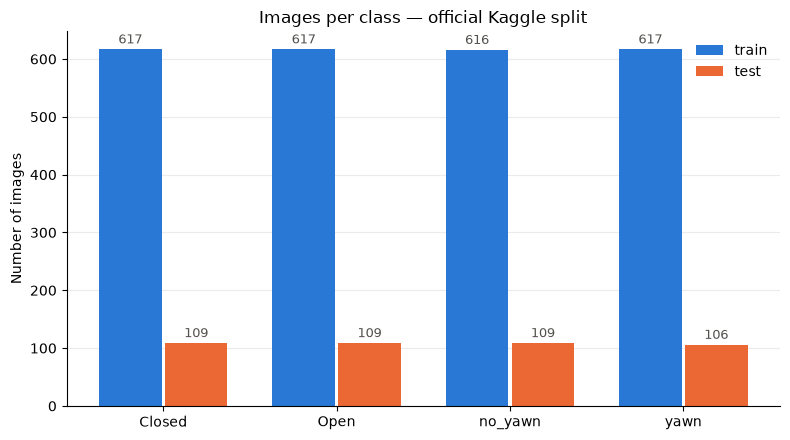

In [6]:
def plot_class_distribution(counts: dict, save_path: Path):
    # Grouped bar chart of images per class for the train and test splits.
    x, width = np.arange(len(CLASSES)), 0.38
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, split in enumerate(["train", "test"]):
        bars = ax.bar(x + (i - 0.5) * width, [counts[split][c] for c in CLASSES], width * 0.95,
                      label=split, color=COLORS[split])
        ax.bar_label(bars, padding=2, fontsize=9, color="#52514e")
    ax.set_xticks(x, CLASSES)
    ax.set_ylabel("Number of images")
    ax.set_title("Images per class — official Kaggle split")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


plot_class_distribution(counts, RESULTS_DIR / "01_class_distribution.png")

## 6. Image properties — two different kinds of images

Looking at image sizes per class reveals something important about this dataset:

- **`Open` / `Closed`** are **close-up crops of a single eye**, with varying sizes.
- **`yawn` / `no_yawn`** are **full video frames** (640×480) of a driver sitting in a car.

**Why this matters for the whole project:** a webcam frame looks like the yawn images, *not* like the eye images.
So in the real-time system the backend must (1) classify the **full frame** for yawning, and (2) **detect and crop the eyes** (OpenCV) before classifying eye state.
Also, because every image is resized to a square, the 4:3 frames get slightly squashed — this is fine as long as inference does the same resize.

In [7]:
def size_summary(info_by_class: dict):
    # Print min / median / max width and height per class.
    print(f"{'class':<10}{'n':>6}   {'width  min/median/max':<24}{'height min/median/max'}")
    for cls in CLASSES:
        w = np.array([r["width"] for r in info_by_class[cls]])
        h = np.array([r["height"] for r in info_by_class[cls]])
        print(f"{cls:<10}{len(w):>6}   {f'{w.min()} / {int(np.median(w))} / {w.max()}':<24}"
              f"{h.min()} / {int(np.median(h))} / {h.max()}")


size_summary({c: train_info[c] + test_info[c] for c in CLASSES})

class          n   width  min/median/max   height min/median/max
Closed       726   67 / 300 / 1625         54 / 300 / 1625
Open         726   50 / 313 / 1514         40 / 300 / 1515
no_yawn      725   640 / 640 / 640         480 / 480 / 480
yawn         723   640 / 640 / 640         480 / 480 / 480


## 7. Sample images from each class

A random selection (fixed seed) from the training split — one row per class, with the original size under each image.

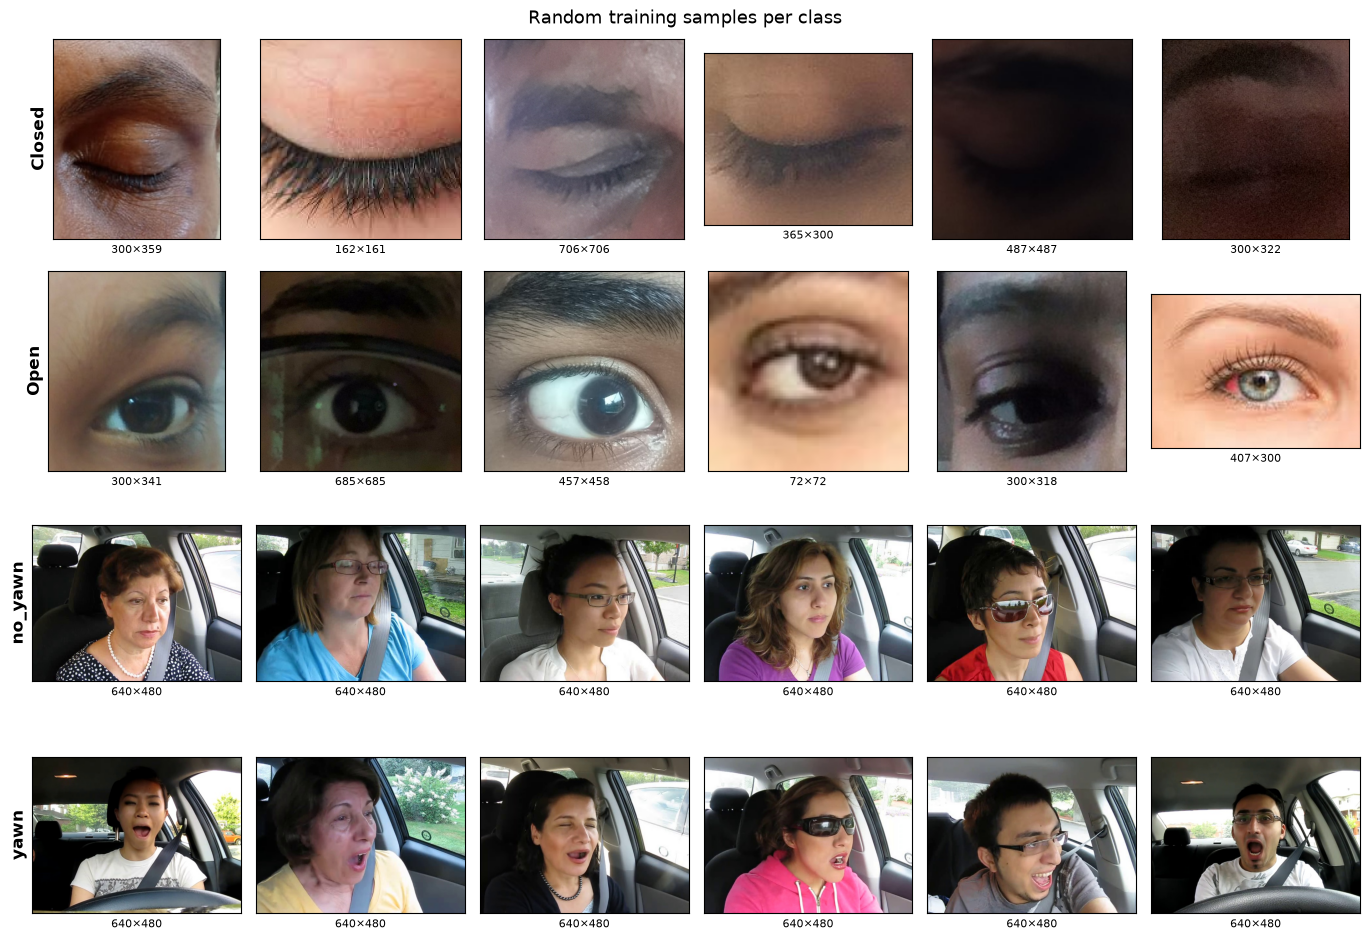

In [8]:
def show_samples(info_by_class: dict, n_per_class: int, save_path: Path):
    # Grid of random images: one row per class.
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(2.3 * n_per_class, 2.4 * len(CLASSES)))
    for row, cls in enumerate(CLASSES):
        picks = rng.choice(len(info_by_class[cls]), n_per_class, replace=False)
        for col, idx in enumerate(picks):
            rec, ax = info_by_class[cls][idx], axes[row, col]
            ax.imshow(Image.open(rec["path"]).convert("RGB"))
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_xlabel(f"{rec['width']}×{rec['height']}", fontsize=8)
            if col == 0:
                ax.set_ylabel(cls, fontsize=12, fontweight="bold")
    fig.suptitle("Random training samples per class", fontsize=13)
    fig.tight_layout()
    fig.savefig(save_path, dpi=120)
    plt.show()


show_samples(train_info, n_per_class=6, save_path=RESULTS_DIR / "01_sample_images.png")

## 8. Train / test leakage check (near-duplicates)

The yawn images are frames cut from **videos**. Consecutive frames of the same person look almost identical — if one frame is in *train* and the next is in *test*, the test set partly measures **memory**, not generalization, and the test accuracy will look better than real-world performance.

**Method — difference hash (dHash):**
1. Shrink each image to 17×16 grayscale (removes detail, keeps structure).
2. For every pixel, record 1 bit: *is it brighter than its left neighbour?* → a 256-bit fingerprint.
3. Two images are **near-duplicates** if their fingerprints differ in ≤ 10 of 256 bits (Hamming distance).

For every test image we find its most similar training image of the same class.

In [9]:
NEAR_DUP_BITS = 10  # fingerprints differing in <= 10 / 256 bits are treated as near-duplicates


def dhash(path: Path, size: int = 16) -> np.ndarray:
    # 256-bit difference-hash fingerprint: stays (almost) the same for visually near-identical images.
    gray = np.asarray(Image.open(path).convert("L").resize((size + 1, size)), dtype=np.int16)
    return (gray[:, 1:] > gray[:, :-1]).flatten()


def nearest_train_match(train_recs: list, test_recs: list):
    # For each test image: (Hamming distance to the closest train image, index of that train image).
    train_h = np.array([dhash(r["path"]) for r in train_recs])
    test_h  = np.array([dhash(r["path"]) for r in test_recs])
    dist = (test_h[:, None, :] != train_h[None, :, :]).sum(axis=2)
    return dist.min(axis=1), dist.argmin(axis=1)


leakage, matches = {}, {}
for cls in CLASSES:
    dist, idx = nearest_train_match(train_info[cls], test_info[cls])
    matches[cls] = (dist, idx)
    leakage[cls] = int((dist <= NEAR_DUP_BITS).sum())
    print(f"{cls:<10}{leakage[cls]:>4} / {len(dist)} test images ({leakage[cls] / len(dist):>4.0%}) "
          f"have a near-duplicate in train   (median distance: {int(np.median(dist))} bits)")

Closed       0 / 109 test images (  0%) have a near-duplicate in train   (median distance: 61 bits)


Open         0 / 109 test images (  0%) have a near-duplicate in train   (median distance: 70 bits)


no_yawn     50 / 109 test images ( 46%) have a near-duplicate in train   (median distance: 12 bits)


yawn        52 / 106 test images ( 49%) have a near-duplicate in train   (median distance: 11 bits)


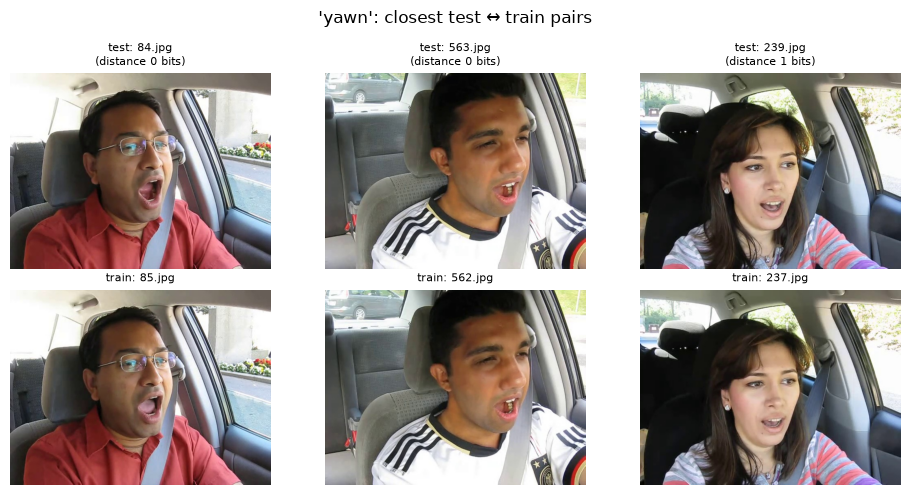

In [10]:
def show_closest_pairs(cls: str, n: int = 3):
    # Show the n test images of `cls` that are most similar to a training image, next to that training image.
    dist, idx = matches[cls]
    fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 5))
    for col, t in enumerate(np.argsort(dist)[:n]):
        for row, (rec, label) in enumerate([(test_info[cls][t], "test"), (train_info[cls][idx[t]], "train")]):
            axes[row, col].imshow(Image.open(rec["path"]).convert("RGB"))
            axes[row, col].set_title(f"{label}: {rec['path'].name}", fontsize=8)
            axes[row, col].axis("off")
        axes[0, col].set_title(f"test: {test_info[cls][t]['path'].name}\n(distance {dist[t]} bits)", fontsize=8)
    fig.suptitle(f"'{cls}': closest test ↔ train pairs", fontsize=12)
    fig.tight_layout()
    plt.show()


show_closest_pairs("yawn")

**Finding:**

- **Eye classes (`Open`, `Closed`): no leakage** — no test image is close to any training image. Eye-state test accuracy is a trustworthy estimate.
- **Yawn classes (`yawn`, `no_yawn`): roughly half** of the test images have a near-identical frame in the training set (same person, same video). Yawn test accuracy will therefore be **optimistic**.

**Decision:** we keep the **official Kaggle split** (so our results are comparable with other work on this dataset), and we **report this caveat** alongside the final metrics. The same effect applies to our validation set, which is carved from the training split below.

## 9. Train / validation split

The model needs three separate sets:

| Split | Source | Used for |
|---|---|---|
| **train** | 85 % of the official train split | learning the weights |
| **val** | 15 % of the official train split | monitoring training, early stopping, choosing the best epoch |
| **test** | the official test split, untouched | the final, honest evaluation — **only once, at the end** |

- **Stratified** split → each class keeps the same proportion in train and val.
- Files are **copied** into `data/processed/<split>/<class>/`, the folder layout Keras' `image_dataset_from_directory` expects.
- The processed folder is deleted and rebuilt on every run, so re-running never mixes an old split with a new one.

In [11]:
def split_train_val(info_by_class: dict):
    # Stratified split of the official train images into our train and val lists.
    records = [r for cls in CLASSES for r in info_by_class[cls]]
    labels  = [r["cls"] for r in records]
    return train_test_split(records, test_size=VAL_SPLIT, stratify=labels, random_state=SEED)


def copy_split(records: list, split_name: str):
    # Copy images into data/processed/<split>/<class>/; non-RGB images are re-saved as RGB JPEG.
    for r in records:
        dst = PROCESSED_DIR / split_name / r["cls"] / r["path"].name
        dst.parent.mkdir(parents=True, exist_ok=True)
        if r["mode"] == "RGB":
            shutil.copy2(r["path"], dst)
        else:
            Image.open(r["path"]).convert("RGB").save(dst, "JPEG", quality=95)


shutil.rmtree(PROCESSED_DIR, ignore_errors=True)
train_recs, val_recs = split_train_val(train_info)
test_recs = [r for cls in CLASSES for r in test_info[cls]]
for name, recs in [("train", train_recs), ("val", val_recs), ("test", test_recs)]:
    copy_split(recs, name)

# Re-count from disk to confirm what was actually written
SPLITS = ["train", "val", "test"]
split_counts = {s: {c: len(list((PROCESSED_DIR / s / c).iterdir())) for c in CLASSES} for s in SPLITS}
print(f"{'class':<10}" + "".join(f"{s:>8}" for s in SPLITS))
for c in CLASSES:
    print(f"{c:<10}" + "".join(f"{split_counts[s][c]:>8}" for s in SPLITS))
print(f"{'TOTAL':<10}" + "".join(f"{sum(split_counts[s].values()):>8}" for s in SPLITS))

class        train     val    test
Closed         524      93     109
Open           524      93     109
no_yawn        524      92     109
yawn           524      93     106
TOTAL         2096     371     433


## 10. Preprocessing

Every image goes through the same two steps before reaching the model:

1. **Resize** to `128 × 128` pixels (bilinear interpolation) — a CNN needs a fixed input size.
2. **Normalize** pixel values from `0–255` to `0–1` (divide by 255) — small, similar-scale inputs make training faster and more stable.

**Design decision — normalization lives *inside* the model.**
In notebook 02 the first layer of the model will be `Rescaling(1/255)`. The backend then only has to send a resized RGB image with raw `0–255` pixels, and the model normalizes it itself.
This rules out a classic deployment bug, where training used `/255` but real-time inference used a different normalization.

The cell below shows the effect on one image per class and prints the numeric range before and after.

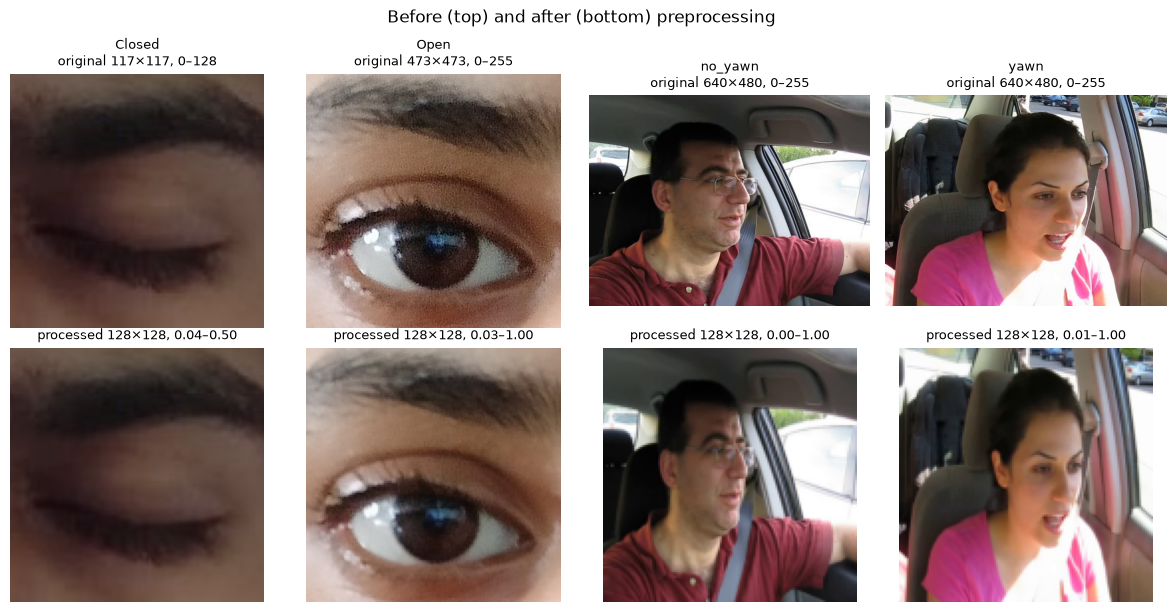

Processed array shape: (128, 128, 3) | dtype: float32


In [12]:
def preprocess(path: Path, img_size: int = IMG_SIZE) -> np.ndarray:
    # What the model sees: RGB, resized to img_size x img_size, pixel values scaled to [0, 1].
    img = Image.open(path).convert("RGB").resize((img_size, img_size), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0


fig, axes = plt.subplots(2, len(CLASSES), figsize=(3 * len(CLASSES), 6.2))
for col, cls in enumerate(CLASSES):
    path = train_recs[[r["cls"] for r in train_recs].index(cls)]["path"]
    original, processed = np.asarray(Image.open(path).convert("RGB")), preprocess(path)
    axes[0, col].imshow(original)
    axes[0, col].set_title(f"{cls}\noriginal {original.shape[1]}×{original.shape[0]}, 0–{original.max()}", fontsize=9)
    axes[1, col].imshow(processed)
    axes[1, col].set_title(f"processed {processed.shape[1]}×{processed.shape[0]}, "
                           f"{processed.min():.2f}–{processed.max():.2f}", fontsize=9)
    for ax in axes[:, col]:
        ax.axis("off")
fig.suptitle("Before (top) and after (bottom) preprocessing", fontsize=12)
fig.tight_layout()
plt.show()

print("Processed array shape:", processed.shape, "| dtype:", processed.dtype)

## 11. Save the data configuration

Later notebooks and the backend must use **exactly** the same classes, image size and normalization as this notebook.
Instead of re-typing these values (and risking a mismatch), we write them to `model/artifacts/data_config.json` — the **single source of truth** for data settings.

Paths are stored **relative to the project root**, so the file still works if the project folder is moved.

In [13]:
data_config = {
    "created": datetime.date.today().isoformat(),
    "dataset": "https://www.kaggle.com/datasets/serenaraju/yawn-eye-dataset-new",
    "classes": CLASSES,
    "img_size": IMG_SIZE,
    "channels": 3,
    "color_mode": "rgb",
    "resize": "bilinear, square (aspect ratio not preserved)",
    "normalization": "x / 255 via a Rescaling layer inside the model -> feed raw 0-255 RGB at inference",
    "val_split": VAL_SPLIT,
    "seed": SEED,
    "paths": {s: f"data/processed/{s}" for s in SPLITS},
    "counts": split_counts,
    "near_duplicate_test_images_in_train": {"threshold_bits": NEAR_DUP_BITS, **leakage},
}

config_path = ARTIFACTS_DIR / "data_config.json"
config_path.write_text(json.dumps(data_config, indent=2))
print("Saved:", config_path)
print(json.dumps(data_config, indent=2))

Saved: D:\MyProj\Clg\DLL Proj1\model\artifacts\data_config.json
{
  "created": "2026-10-01",
  "dataset": "https://www.kaggle.com/datasets/serenaraju/yawn-eye-dataset-new",
  "classes": [
    "Closed",
    "Open",
    "no_yawn",
    "yawn"
  ],
  "img_size": 128,
  "channels": 3,
  "color_mode": "rgb",
  "resize": "bilinear, square (aspect ratio not preserved)",
  "normalization": "x / 255 via a Rescaling layer inside the model -> feed raw 0-255 RGB at inference",
  "val_split": 0.15,
  "seed": 42,
  "paths": {
    "train": "data/processed/train",
    "val": "data/processed/val",
    "test": "data/processed/test"
  },
  "counts": {
    "train": {
      "Closed": 524,
      "Open": 524,
      "no_yawn": 524,
      "yawn": 524
    },
    "val": {
      "Closed": 93,
      "Open": 93,
      "no_yawn": 92,
      "yawn": 93
    },
    "test": {
      "Closed": 109,
      "Open": 109,
      "no_yawn": 109,
      "yawn": 106
    }
  },
  "near_duplicate_test_images_in_train": {
    "threshold

## 12. Summary

In [14]:
total = {s: sum(split_counts[s].values()) for s in SPLITS}
print(f"Images      : {sum(total.values())}  (train {total['train']} | val {total['val']} | test {total['test']})")
print(f"Classes     : {CLASSES}")
print(f"Balance     : imbalance ratio {imbalance:.3f} -> no class weighting needed")
print(f"Corrupt     : {len(train_bad + test_bad)} | non-RGB converted: {len(non_rgb)}")
print(f"Leakage     : near-duplicate test images in train -> {leakage}")
print(f"Image size  : {IMG_SIZE}x{IMG_SIZE} RGB, normalized inside the model")
print("Outputs     : data/processed/, model/artifacts/data_config.json, model/results/01_*.png")

Images      : 2900  (train 2096 | val 371 | test 433)
Classes     : ['Closed', 'Open', 'no_yawn', 'yawn']
Balance     : imbalance ratio 1.002 -> no class weighting needed
Corrupt     : 0 | non-RGB converted: 2
Leakage     : near-duplicate test images in train -> {'Closed': 0, 'Open': 0, 'no_yawn': 50, 'yawn': 52}
Image size  : 128x128 RGB, normalized inside the model
Outputs     : data/processed/, model/artifacts/data_config.json, model/results/01_*.png


**Key takeaways for the viva**

1. The dataset is **balanced** (~617 train images per class), so plain accuracy is a meaningful metric and no class weighting is needed.
2. It contains **two image types** — eye crops and full driver frames — which shapes the real-time design (full frame → yawn, eye crops → open/closed).
3. **Eye-class test results are trustworthy; yawn-class test results are optimistic** because of near-duplicate video frames across the official split.
4. Validation data is carved from the training split, so the **test set is never used for training decisions** (a common mistake that inflates reported accuracy).
5. Normalization is placed **inside the model**, so training and deployment cannot disagree on preprocessing.

**Next → `02_model_training.ipynb`:** build the data pipeline with augmentation and train the baseline custom CNN.